# Rol 1. Líder de modelado (Majo)

**Task 1.1.** En este notebook se analizan las curvas de pérdida y la tabla de umbrales del modelo candidato de RemesaSegura. Con esos datos se recomienda cómo debe entrenarse el modelo y se redacta la sección 1 del memo.

Se agrega la raíz del repositorio al `sys.path` para importar los módulos de `src/`. Los datos del enunciado están en `src/case_data.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import case_data as cd

import matplotlib.pyplot as plt
from src.metrics import precision_at_prevalence

## 1. Curvas de pérdida

El enunciado reporta solo algunos puntos de las curvas. Las celdas vacías (`NaN`) corresponden a valores no reportados.

In [2]:
losses = cd.training_losses()
losses

,epoca,perdida_entrenamiento,perdida_validacion
0,1,0.42,NaN
1,6,NaN,0.21
2,20,0.08,0.34


In [3]:
val_min = losses["perdida_validacion"].min()
val_last = losses["perdida_validacion"].iloc[-1]
train_last = losses["perdida_entrenamiento"].iloc[-1]
print(f"Aumento de la pérdida de validación desde su mínimo: {val_last - val_min:.2f}")
print(f"Brecha validación - entrenamiento en la época 20: {val_last - train_last:.2f}")

Aumento de la pérdida de validación desde su mínimo: 0.13
Brecha validación - entrenamiento en la época 20: 0.26


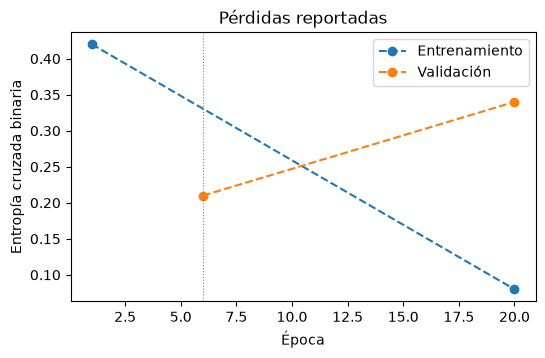

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for col, label in [("perdida_entrenamiento", "Entrenamiento"), ("perdida_validacion", "Validación")]:
    pts = losses.dropna(subset=[col])
    ax.plot(pts["epoca"], pts[col], "o--", label=label)
ax.axvline(6, color="gray", lw=0.8, ls=":")
ax.set(xlabel="Época", ylabel="Entropía cruzada binaria", title="Pérdidas reportadas")
ax.legend()
plt.show()

### a. Diagnóstico y dos cambios de entrenamiento

La pérdida de entrenamiento baja hasta 0.08, mientras que la de validación sube 0.13 desde su mínimo de la época 6. En la época 20 la brecha entre ambas es de 0.26. Este patrón corresponde a **sobreajuste**. A partir de la época 6 el modelo memoriza el conjunto de entrenamiento y empeora en datos que no ha visto. Además, el modelo evaluado es el de la época 20, que es el peor punto de validación reportado.

Se proponen dos cambios.

1. **Detención temprana con restauración del mejor modelo.** Corrige que se entregue un modelo sobreajustado. Se conserva el modelo con menor pérdida de validación (0.21, cerca de la época 6) en lugar del de la época 20 (0.34).
2. **Regularización explícita (weight decay y dropout).** Corrige la memorización. Penaliza pesos grandes y obliga a la red a no depender de pocas neuronas, lo que reduce la brecha entre entrenamiento y validación.

## 2. Función de pérdida

Con una clase positiva de 0.2%, se calcula el peso que equilibraría ambas clases en la entropía cruzada binaria. Este peso es el cociente entre negativos y positivos.

In [5]:
pos_weight = (1 - cd.PREVALENCE) / cd.PREVALENCE
print(f"Peso de la clase positiva para BCE ponderada: {pos_weight:.0f}")

Peso de la clase positiva para BCE ponderada: 499


### b. ¿Es apropiada la entropía cruzada sin ponderar?

No es apropiada. Con 0.2% de positivos, casi toda la pérdida proviene de los negativos, y el modelo puede reducirla prediciendo casi siempre "normal". Los pocos casos de lavado aportan muy poco al gradiente.

Se propone usar **entropía cruzada binaria ponderada** con un peso de 499 para la clase positiva, según el resultado anterior. Así cada positivo pesa lo mismo que 499 negativos y ambas clases contribuyen por igual a la pérdida. Una alternativa es la **focal loss**, que reduce el peso de los ejemplos fáciles (la mayoría de negativos) y concentra el aprendizaje en los casos difíciles. En ambos casos el peso o el parámetro de la focal loss se ajusta con un conjunto de validación en proporción real.

## 3. Tabla de umbrales a prevalencia real

La tabla del enunciado se calculó con un conjunto de validación balanceado (50% positivos). El recall y la tasa de falsos positivos no dependen de la proporción de clases, pero la precisión sí. Por eso se recalcula la precisión con la prevalencia real de 0.2%.

In [6]:
table = cd.thresholds()
table["precision_real"] = [
    precision_at_prevalence(r, f, cd.PREVALENCE) for r, f in zip(table["recall"], table["fpr"])
]
table.round(4)

,umbral,recall,fpr,precision_balanceada,precision_real
0,U1,0.90,0.100,0.90,0.0177
1,U2,0.80,0.040,0.95,0.0385
2,U3,0.65,0.010,0.98,0.1152
3,U4,0.50,0.005,0.99,0.1669


La precisión de U2 pasa de 0.95 en el conjunto balanceado a 0.0385 con la prevalencia real. Ningún umbral supera una precisión de 0.17. Las precisiones de la tabla original no describen lo que verá el equipo de cumplimiento.

### c. Sección 1 del memo

> **1. Modelado.** Se recomienda no usar el modelo de la época 20. Su pérdida de validación subió de 0.21 (época 6) a 0.34, lo que indica sobreajuste. El modelo debe reentrenarse con detención temprana, regularización y entropía cruzada ponderada (peso positivo de 499). Además, la precisión de la tabla proviene de un conjunto balanceado. A la prevalencia real, U2 tiene una precisión de 3.85% y no de 95%, por lo que todas las métricas deben recalcularse con la proporción real.